In [8]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram


In [9]:
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAMPLE_LIMIT = 12000

In [10]:
original_df = pd.read_csv('Online.csv', encoding='latin1')
print("Shape:",original_df.shape)
display(original_df.head())

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [11]:
display(pd.DataFrame({
    "Data Type": original_df.dtypes.astype(str),
    "Missing Values": original_df.isna().sum(),
    "Unique Values": original_df.nunique()
}))
display(original_df.describe(include="all").T)
print("Duplicate rows:", original_df.duplicated().sum())
print("Columns:", original_df.columns.tolist())


,Data Type,Missing Values,Unique Values
InvoiceNo,str,0,25900
StockCode,str,0,4070
Description,str,1454,4223
Quantity,int64,0,722
InvoiceDate,str,0,23260
UnitPrice,float64,0,1630
CustomerID,float64,135080,4372
Country,str,0,38


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,31-10-2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 5268
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [12]:
df = original_df.copy()
df.columns = df.columns.str.strip()
required = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")
df = df.drop_duplicates()
df = df.dropna(subset=["CustomerID", "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"])
df["CustomerID"] = df["CustomerID"].astype(str).str.replace(r"\.0$", "", regex=True)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df = df.dropna(subset=["InvoiceDate"])
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df["Sales"] = df["Quantity"] * df["UnitPrice"]
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
customer_df = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    AverageOrderValue=("Sales", "mean"),
    Country=("Country", lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
).reset_index()
customer_df = customer_df.replace([np.inf, -np.inf], np.nan).dropna()
print("Customer-level shape:", customer_df.shape)
display(customer_df.head())
display(customer_df.describe(include="all").T)


Customer-level shape: (2997, 8)


,CustomerID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue,Country
0,12347,96,5,2540.29,1467,79,23.965000,Iceland
1,12348,221,1,367.00,269,5,73.400000,Finland
2,12350,312,1,334.40,197,17,19.670588,Norway
3,12352,275,3,1296.38,156,20,56.364348,Norway
4,12355,97,1,459.40,240,13,35.338462,Bahrain


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,2997,2997,12347,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Recency,2997.0,NaN,NaN,NaN,155.387387,140.13812,1.0,40.0,125.0,219.0,698.0
Frequency,2997.0,NaN,NaN,NaN,2.656323,4.008919,1.0,1.0,2.0,3.0,106.0
Monetary,2997.0,NaN,NaN,NaN,1289.777471,5273.011876,5.9,244.41,466.29,1064.28,168469.6
TotalQuantity,2997.0,NaN,NaN,NaN,733.845846,2717.321877,1.0,120.0,268.0,646.0,80995.0
UniqueProducts,2997.0,NaN,NaN,NaN,44.085419,62.021482,1.0,13.0,26.0,54.0,1193.0
AverageOrderValue,2997.0,NaN,NaN,NaN,97.54351,3089.154947,1.257551,12.507891,18.034333,25.92,168469.6
Country,2997,33,United Kingdom,2713,NaN,NaN,NaN,NaN,NaN,NaN,NaN


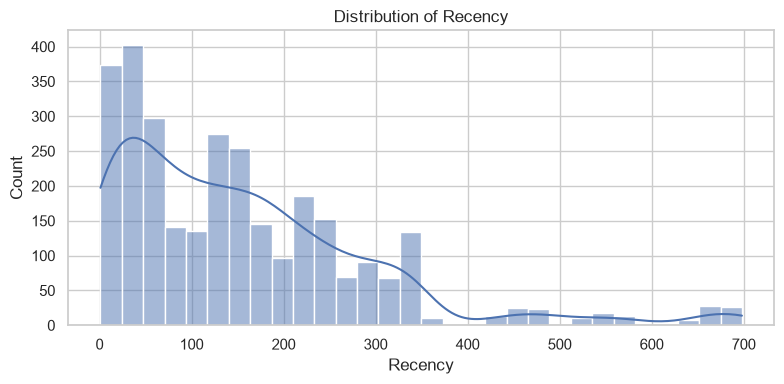

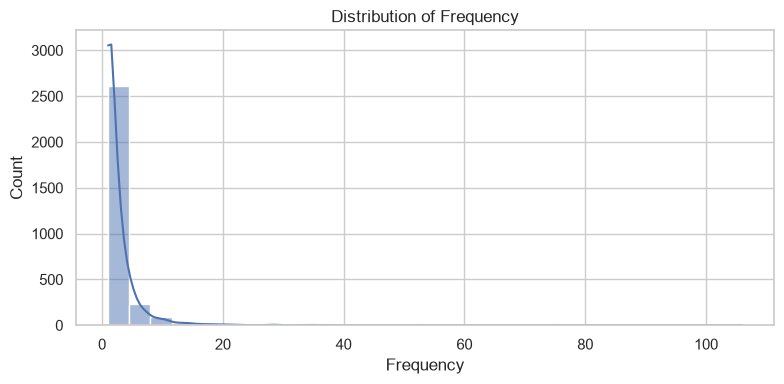

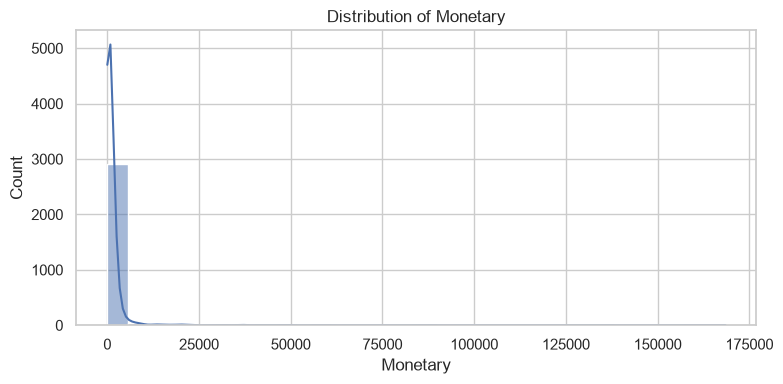

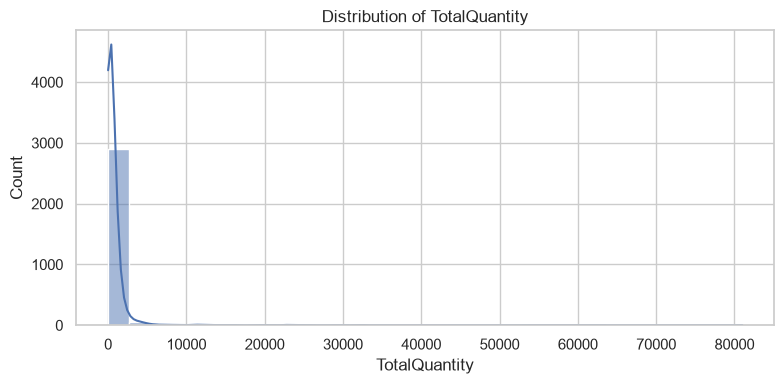

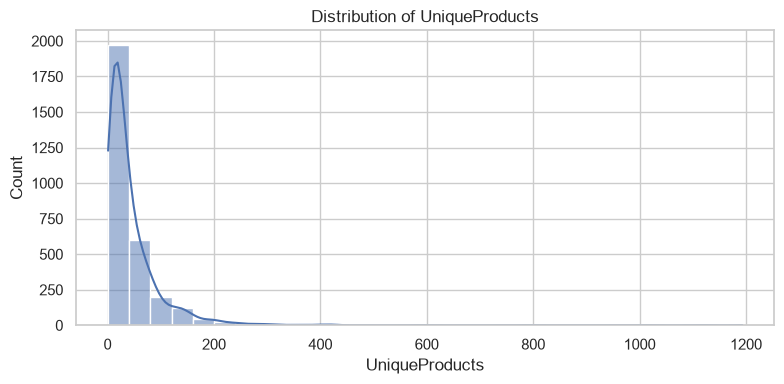

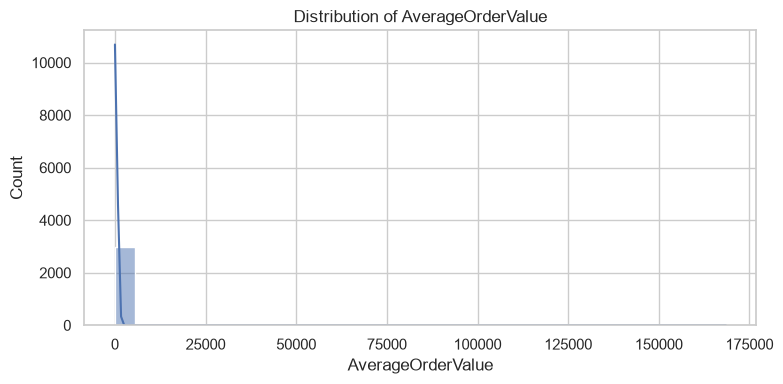

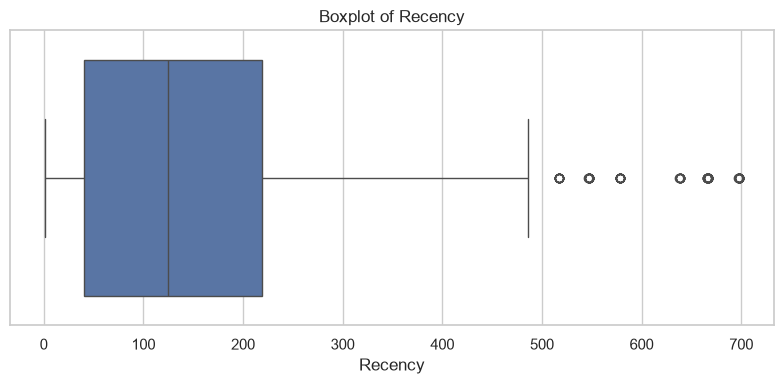

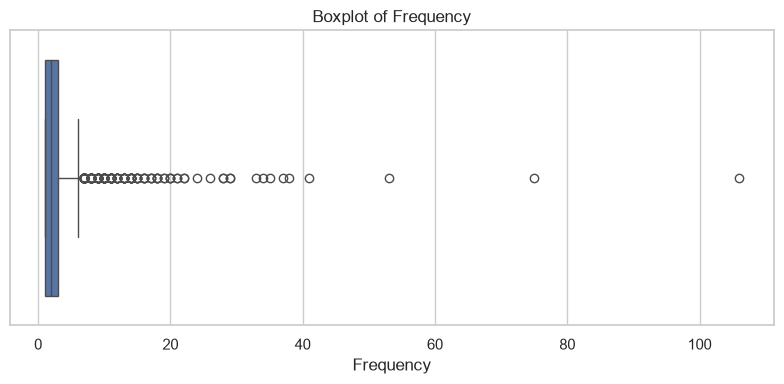

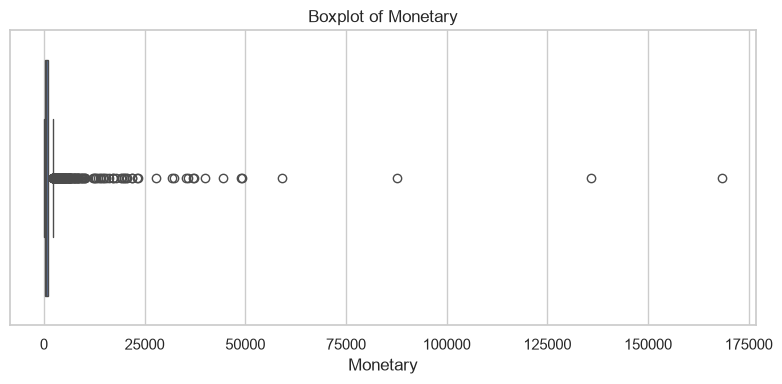

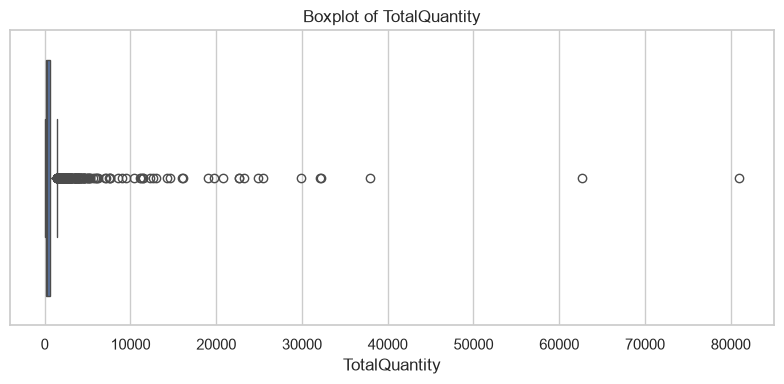

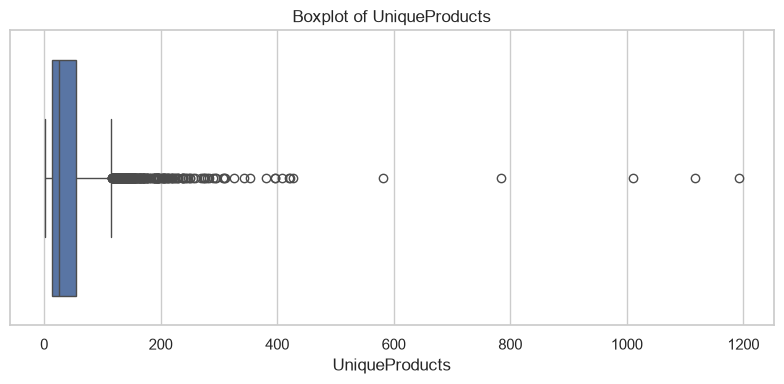

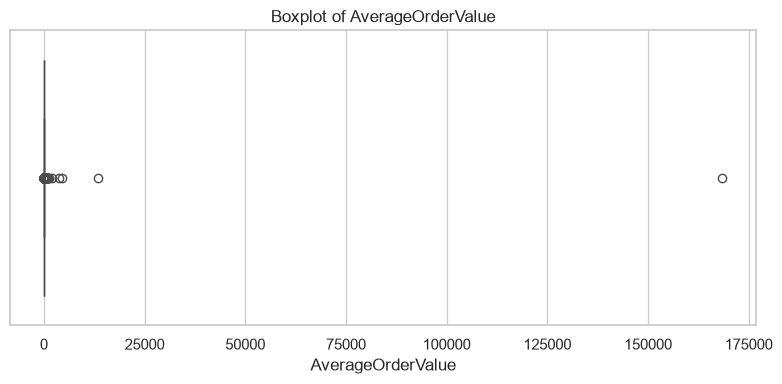

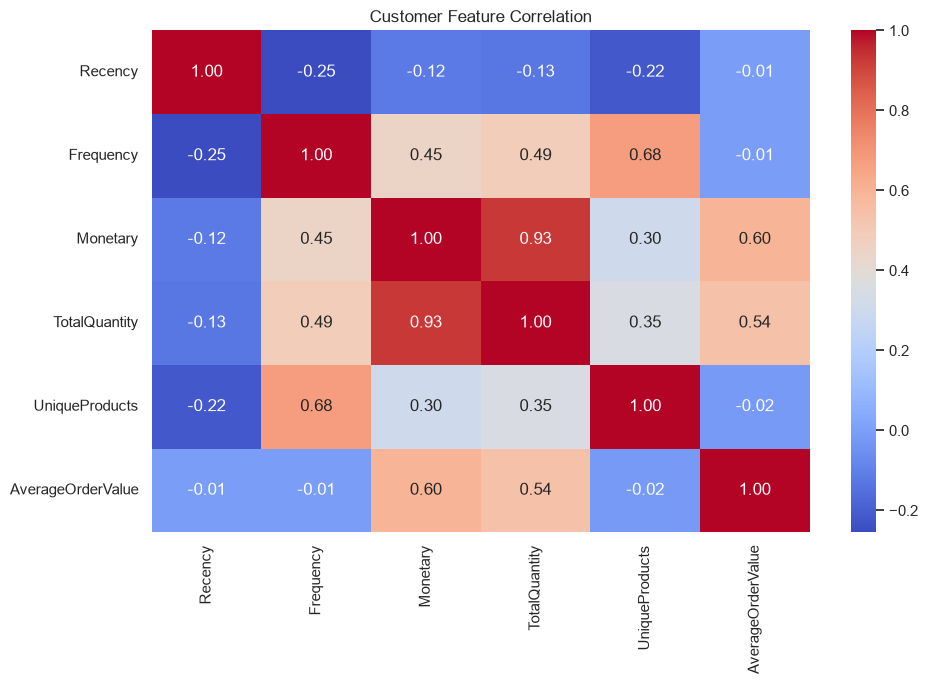

In [13]:
numeric_cols = customer_df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = customer_df.select_dtypes(exclude=np.number).columns.tolist()
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(customer_df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=customer_df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()
for col in categorical_cols:
    if customer_df[col].nunique() <= 20:
        plt.figure(figsize=(10, 4))
        customer_df[col].value_counts().head(20).plot(kind="bar")
        plt.title(f"Top categories: {col}")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
plt.figure(figsize=(10, 7))
sns.heatmap(customer_df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Customer Feature Correlation")
plt.tight_layout()
plt.show()


Modeling sample shape: (2997, 6)
PCA explained variance: [0.48134971 0.24679447] Total: 0.7281441730740391


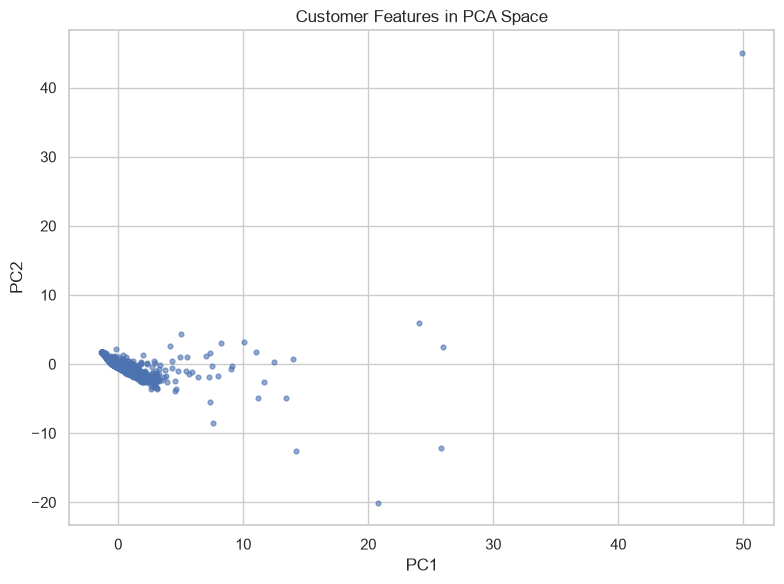

In [14]:
feature_cols = ["Recency", "Frequency", "Monetary", "TotalQuantity", "UniqueProducts", "AverageOrderValue"]
X_raw = customer_df[feature_cols].copy()
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)
scaler = StandardScaler()
X_scaled_full = scaler.fit_transform(X_imputed)
if len(X_scaled_full) > SAMPLE_LIMIT:
    rng = np.random.default_rng(RANDOM_STATE)
    sample_indices = np.sort(rng.choice(len(X_scaled_full), SAMPLE_LIMIT, replace=False))
else:
    sample_indices = np.arange(len(X_scaled_full))
X_scaled = X_scaled_full[sample_indices]
customers = customer_df.iloc[sample_indices].reset_index(drop=True).copy()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Modeling sample shape:", X_scaled.shape)
print("PCA explained variance:", pca.explained_variance_ratio_, "Total:", pca.explained_variance_ratio_.sum())
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=12, alpha=0.6)
plt.title("Customer Features in PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()


In [15]:
def evaluate_labels(X, labels):
    labels = np.asarray(labels)
    non_noise = labels != -1
    valid_labels = labels[non_noise]
    unique = np.unique(valid_labels)
    if len(unique) < 2 or non_noise.sum() <= len(unique):
        return {
            "Clusters": len(unique),
            "Noise Points": int(np.sum(labels == -1)),
            "Silhouette": np.nan,
            "Calinski-Harabasz": np.nan,
            "Davies-Bouldin": np.nan
        }
    X_eval = X[non_noise]
    return {
        "Clusters": len(unique),
        "Noise Points": int(np.sum(labels == -1)),
        "Silhouette": silhouette_score(X_eval, valid_labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_eval, valid_labels),
        "Davies-Bouldin": davies_bouldin_score(X_eval, valid_labels)
    }

def plot_clusters(labels, title):
    plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Cluster": np.asarray(labels).astype(str)})
    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=35, alpha=0.8)
    plt.title(title)
    plt.tight_layout()
    plt.show()

def show_profile(labels, title):
    temp = customers[feature_cols].copy()
    temp["Cluster"] = np.asarray(labels)
    profile = temp.groupby("Cluster")[feature_cols].median().round(2)
    display(profile)
    counts = temp["Cluster"].value_counts().sort_index()
    plt.figure(figsize=(8, 4))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title(f"{title}: Cluster Sizes")
    plt.xlabel("Cluster")
    plt.ylabel("Customers")
    plt.tight_layout()
    plt.show()
    for col in ["Recency", "Frequency", "Monetary", "AverageOrderValue"]:
        plt.figure(figsize=(8, 4))
        sns.boxplot(data=temp, x="Cluster", y=col)
        plt.title(f"{title}: {col} by Cluster")
        plt.tight_layout()
        plt.show()
    return profile


,K,Inertia,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,13129.557844,2,0,0.971924,1106.896700,0.019020
1,3,9249.532252,3,0,0.878718,1413.315167,0.569957
2,4,7142.585798,4,0,0.339003,1514.036655,0.762498
3,5,5697.753905,5,0,0.398449,1612.673385,0.787547
4,6,4609.632568,6,0,0.398148,1735.355276,0.738113
5,7,3928.188209,7,0,0.409826,1782.878646,0.698812
6,8,3301.159364,8,0,0.374469,1898.991305,0.693309


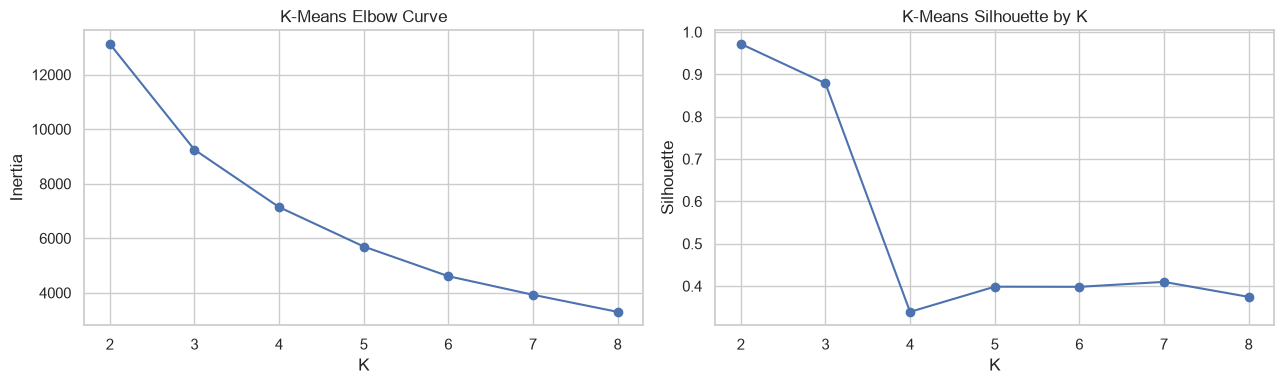

Selected K: 2


,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0,0.971924,1106.8967,0.01902


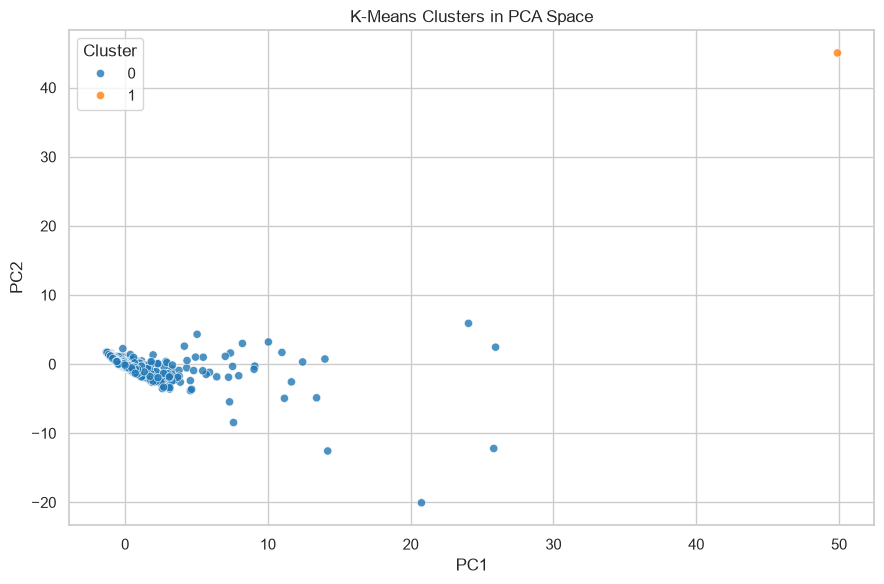

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
0,125.5,2.0,466.22,268.0,26.0,18.03
1,90.0,1.0,168469.60,80995.0,1.0,168469.60


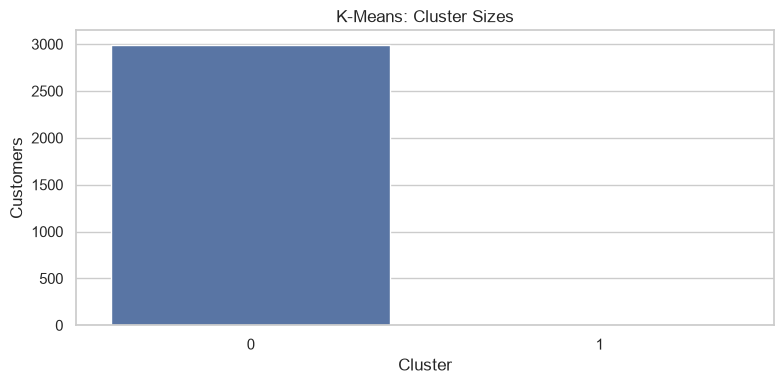

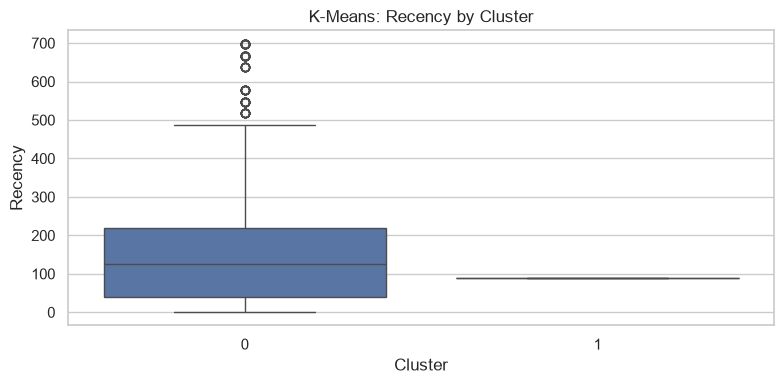

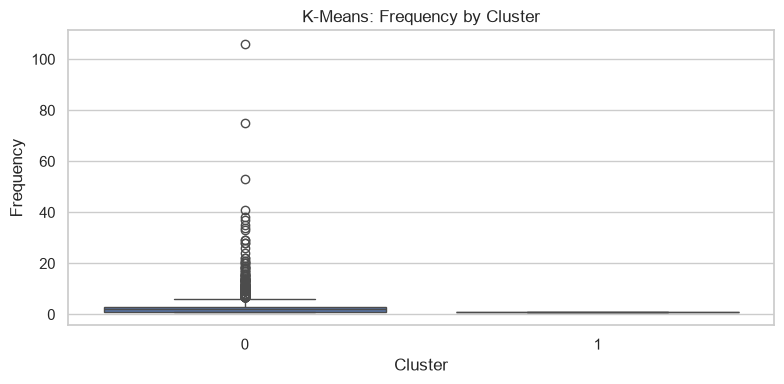

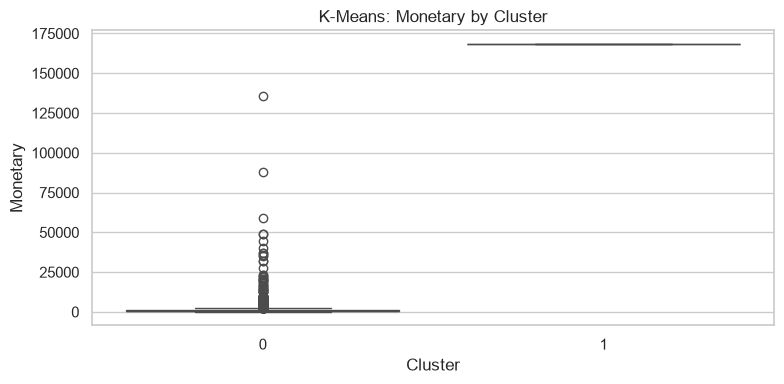

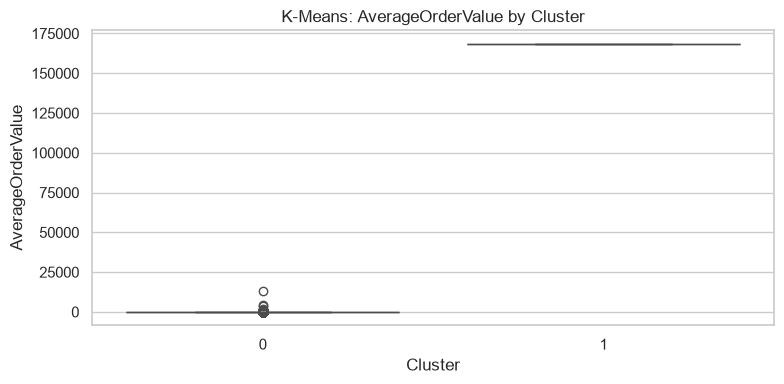

In [16]:
kmeans_rows = []
kmeans_models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    metrics = evaluate_labels(X_scaled, labels)
    kmeans_rows.append({"K": k, "Inertia": model.inertia_, **metrics})
    kmeans_models[k] = (model, labels)
kmeans_results = pd.DataFrame(kmeans_rows)
display(kmeans_results)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(kmeans_results["K"], kmeans_results["Inertia"], marker="o")
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[1].plot(kmeans_results["K"], kmeans_results["Silhouette"], marker="o")
axes[1].set_title("K-Means Silhouette by K")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()
best_kmeans_k = int(kmeans_results.loc[kmeans_results["Silhouette"].idxmax(), "K"])
kmeans_model, kmeans_labels = kmeans_models[best_kmeans_k]
print("Selected K:", best_kmeans_k)
display(pd.DataFrame([evaluate_labels(X_scaled, kmeans_labels)]))
plot_clusters(kmeans_labels, "K-Means Clusters in PCA Space")
kmeans_profile = show_profile(kmeans_labels, "K-Means")


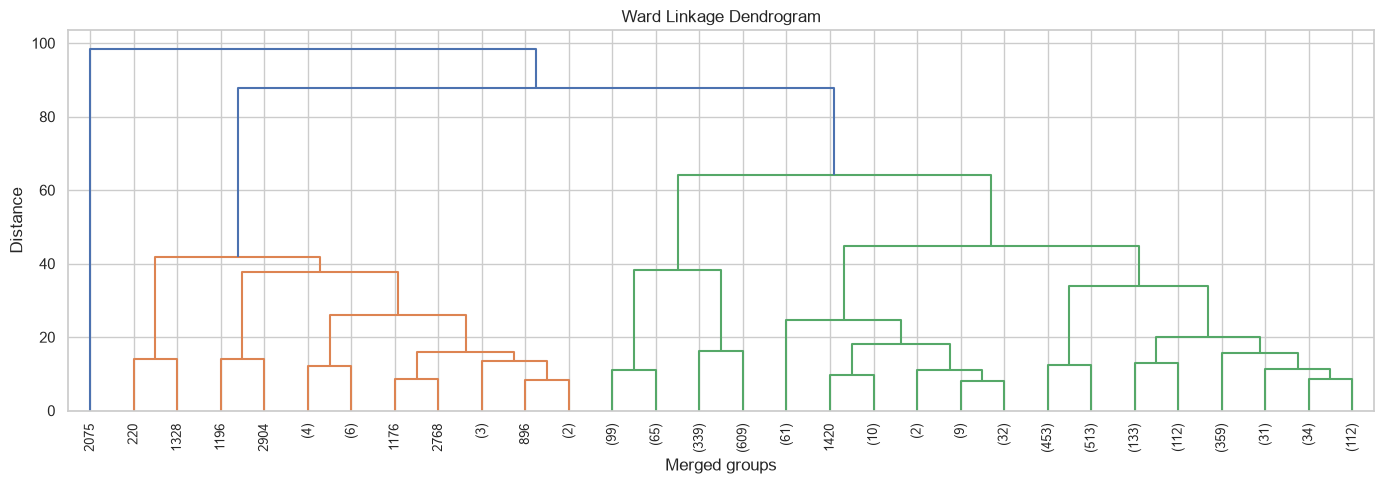

,K,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,2,0,0.971924,1106.896700,0.019020
1,3,3,0,0.880902,1408.352165,0.568075
2,4,4,0,0.326237,1492.877139,0.771816
3,5,5,0,0.354167,1422.534726,0.867471
4,6,6,0,0.354885,1421.420650,0.810825
5,7,7,0,0.331425,1452.436188,0.788438
6,8,8,0,0.332227,1550.950431,0.767758


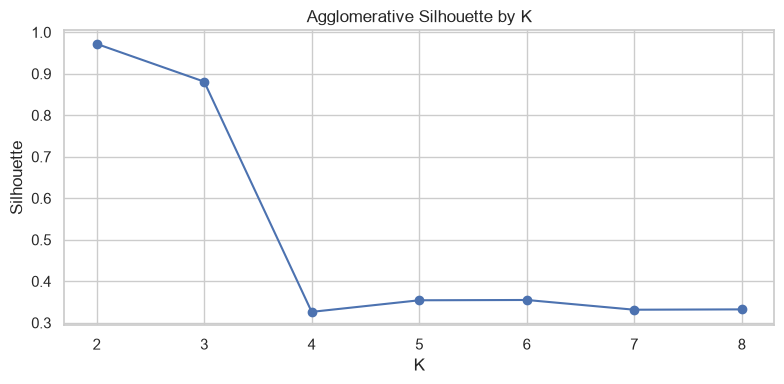

Selected K: 2


,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0,0.971924,1106.8967,0.01902


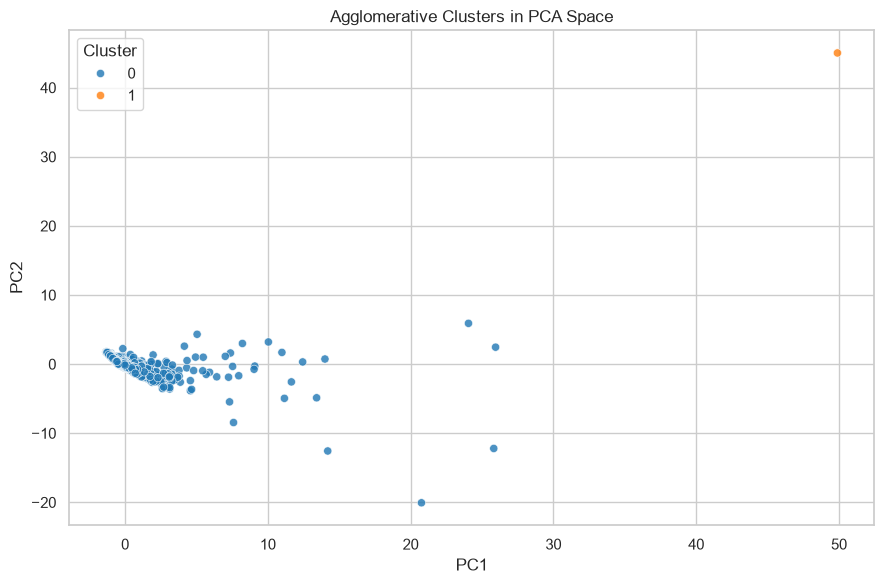

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
0,125.5,2.0,466.22,268.0,26.0,18.03
1,90.0,1.0,168469.60,80995.0,1.0,168469.60


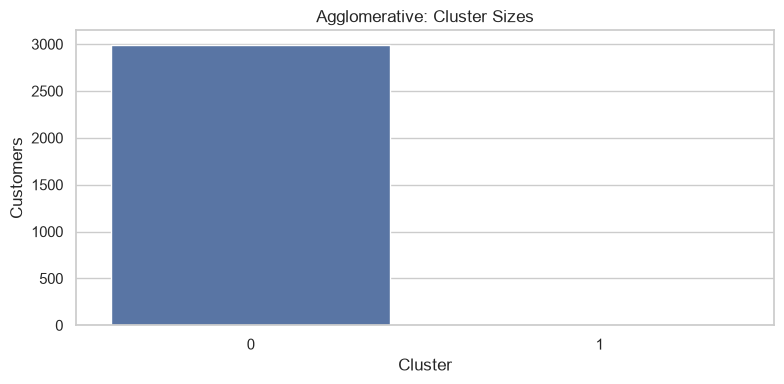

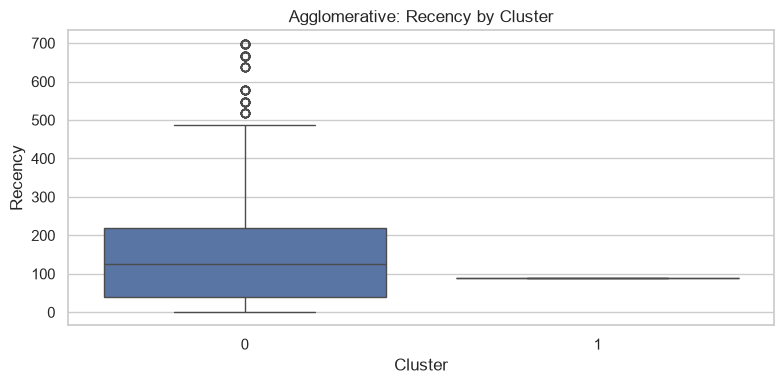

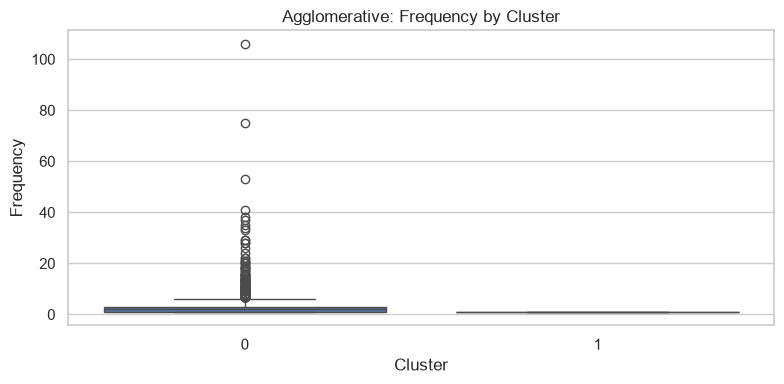

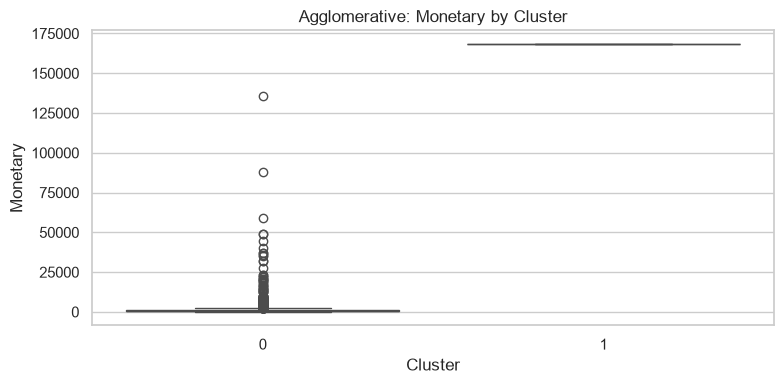

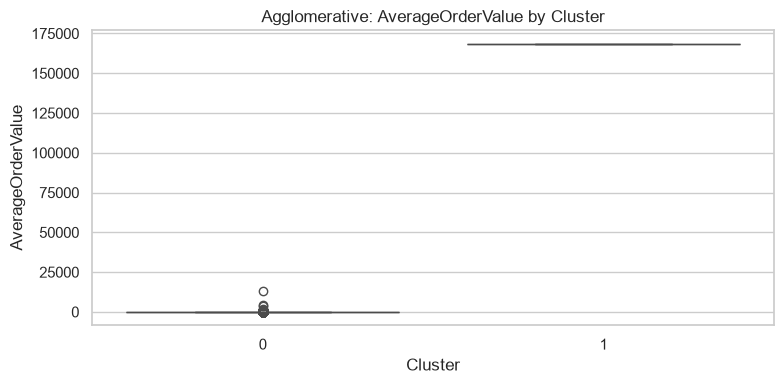

In [17]:
linkage_matrix = linkage(X_scaled, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9)
plt.title("Ward Linkage Dendrogram")
plt.xlabel("Merged groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()
agg_rows = []
agg_models = {}
for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    agg_rows.append({"K": k, **evaluate_labels(X_scaled, labels)})
    agg_models[k] = (model, labels)
agg_results = pd.DataFrame(agg_rows)
display(agg_results)
plt.figure(figsize=(8, 4))
plt.plot(agg_results["K"], agg_results["Silhouette"], marker="o")
plt.title("Agglomerative Silhouette by K")
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.tight_layout()
plt.show()
best_agg_k = int(agg_results.loc[agg_results["Silhouette"].idxmax(), "K"])
agg_model, agg_labels = agg_models[best_agg_k]
print("Selected K:", best_agg_k)
display(pd.DataFrame([evaluate_labels(X_scaled, agg_labels)]))
plot_clusters(agg_labels, "Agglomerative Clusters in PCA Space")
agg_profile = show_profile(agg_labels, "Agglomerative")


,K,Medoid Cost,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,3178.961566,2,0,0.291693,438.537952,1.215797
1,3,2987.161522,3,0,0.330065,377.823049,1.101776
2,4,2482.816007,4,0,0.236080,355.666122,1.103908
3,5,2382.076845,5,0,0.236676,309.033794,1.220746
4,6,2249.443753,6,0,0.183275,317.534315,1.252729


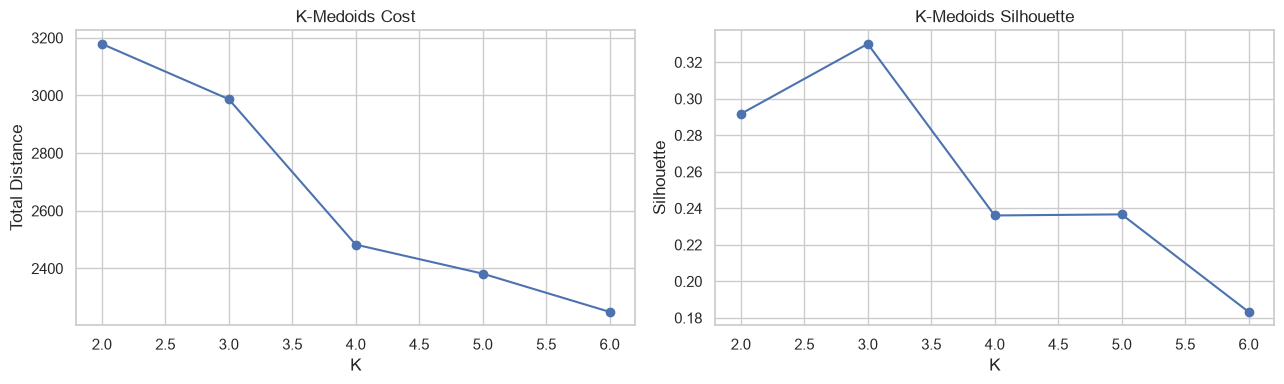

Selected K: 3 Medoid cost: 2987.162


,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,3,0,0.330065,377.823049,1.101776


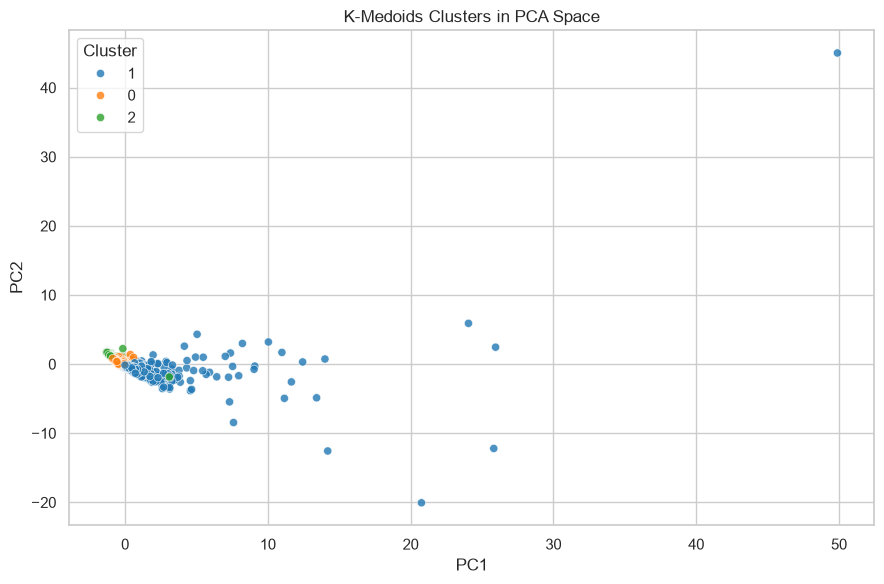

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
0,161.0,1.0,317.58,173.5,17.0,18.51
1,38.0,4.0,1357.80,800.0,69.0,17.50
2,547.0,1.0,230.40,108.0,14.0,16.89


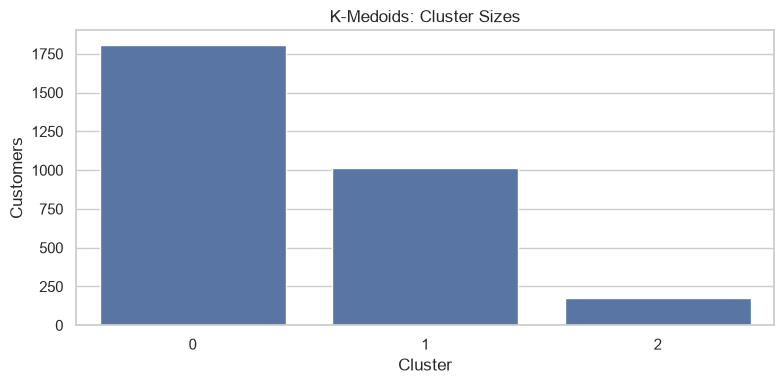

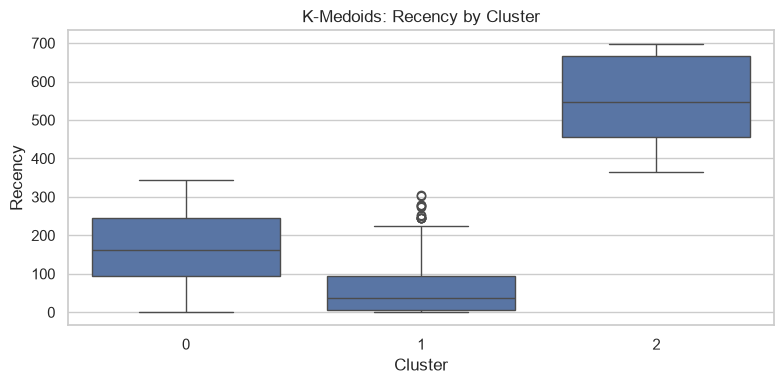

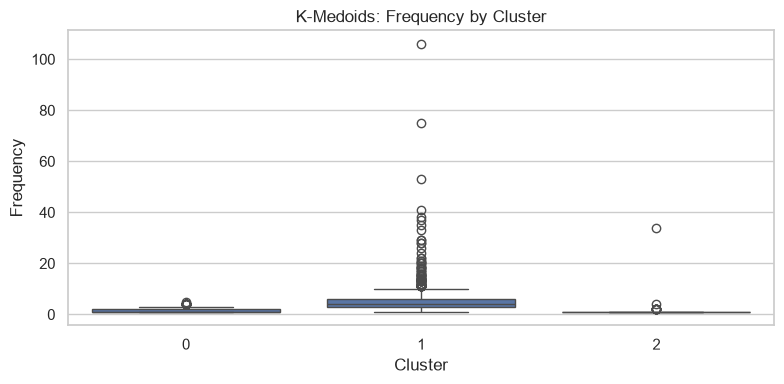

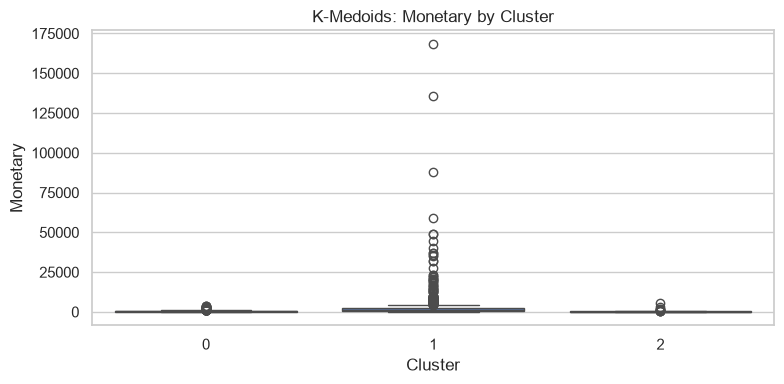

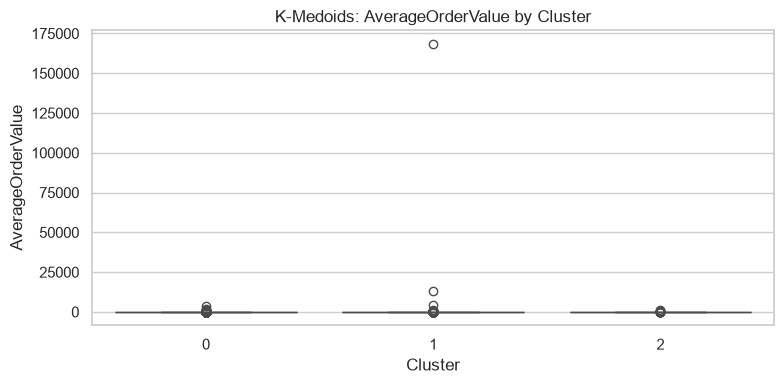

In [18]:
def kmedoids_fit(X, n_clusters, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    n = len(X)
    medoid_idx = rng.choice(n, n_clusters, replace=False)
    distances = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    for _ in range(max_iter):
        labels = distances[:, medoid_idx].argmin(axis=1)
        new_medoids = medoid_idx.copy()
        for cluster_id in range(n_clusters):
            members = np.where(labels == cluster_id)[0]
            if len(members) == 0:
                continue
            intra = distances[np.ix_(members, members)]
            new_medoids[cluster_id] = members[np.argmin(intra.sum(axis=1))]
        if np.array_equal(new_medoids, medoid_idx):
            break
        medoid_idx = new_medoids
    labels = distances[:, medoid_idx].argmin(axis=1)
    return labels, medoid_idx, float(distances[np.arange(n), medoid_idx[labels]].sum())

kmedoid_rows = []
kmedoid_models = {}
for k in range(2, 7):
    labels, medoids, cost = kmedoids_fit(X_scaled, k, max_iter=50, random_state=RANDOM_STATE)
    kmedoid_rows.append({"K": k, "Medoid Cost": cost, **evaluate_labels(X_scaled, labels)})
    kmedoid_models[k] = (labels, medoids, cost)
kmedoid_results = pd.DataFrame(kmedoid_rows)
display(kmedoid_results)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(kmedoid_results["K"], kmedoid_results["Medoid Cost"], marker="o")
axes[0].set_title("K-Medoids Cost")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Total Distance")
axes[1].plot(kmedoid_results["K"], kmedoid_results["Silhouette"], marker="o")
axes[1].set_title("K-Medoids Silhouette")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()
best_kmedoid_k = int(kmedoid_results.loc[kmedoid_results["Silhouette"].idxmax(), "K"])
kmedoid_labels, kmedoid_indices, kmedoid_cost = kmedoid_models[best_kmedoid_k]
print("Selected K:", best_kmedoid_k, "Medoid cost:", round(kmedoid_cost, 3))
display(pd.DataFrame([evaluate_labels(X_scaled, kmedoid_labels)]))
plot_clusters(kmedoid_labels, "K-Medoids Clusters in PCA Space")
kmedoid_profile = show_profile(kmedoid_labels, "K-Medoids")


,C,Objective,Partition Coefficient,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,8730.031763,0.341080,2,0,0.291757,438.895860,1.231223
1,3,5572.873782,0.215549,3,0,0.353686,512.064587,1.140558
2,4,4132.683375,0.143562,4,0,0.329725,486.987162,1.242721
3,5,3228.234918,0.112915,5,0,0.352066,433.807554,1.153787
4,6,2560.647409,0.091169,6,0,0.351784,659.522904,1.088637
5,7,2158.389671,0.071929,7,0,0.305396,577.534986,1.083810


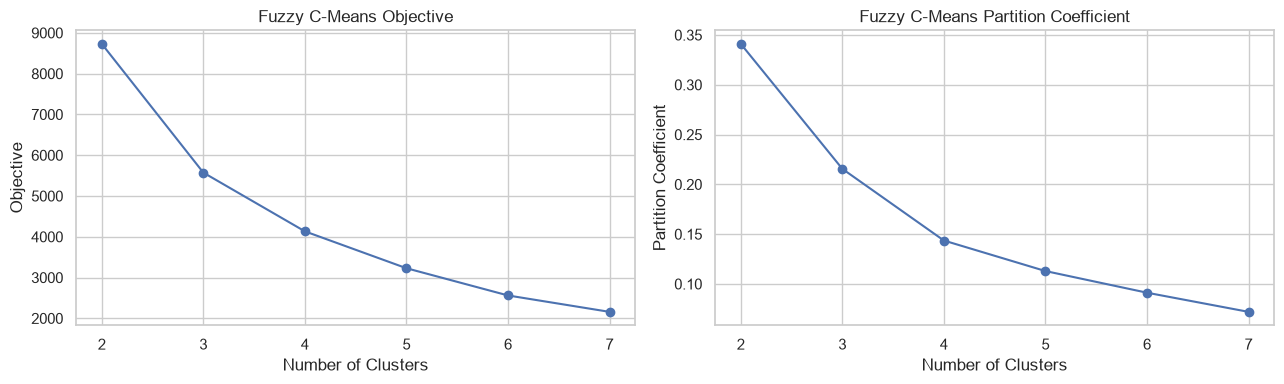

Selected clusters: 3


,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,3,0,0.353686,512.064587,1.140558


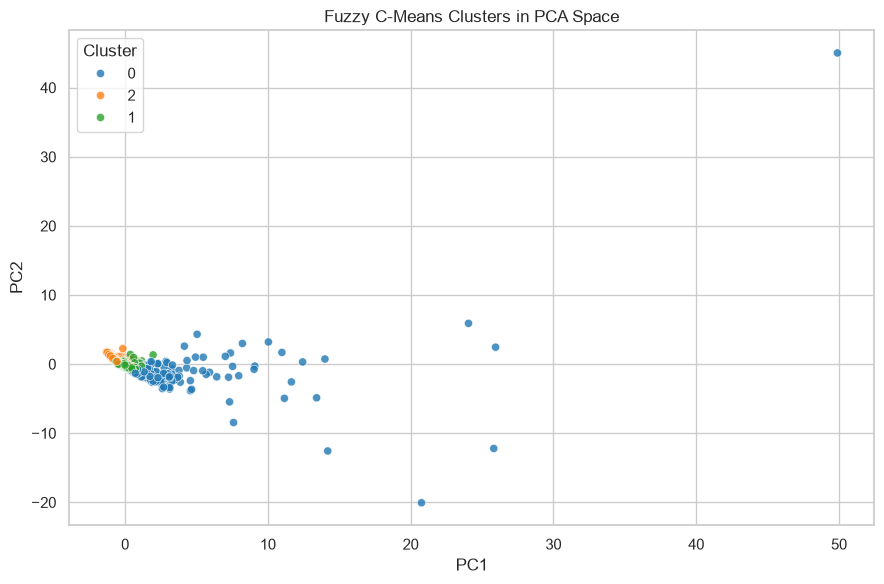

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
0,38.0,6.0,2365.32,1340.0,122.0,16.98
1,90.0,2.0,481.24,274.0,25.0,18.32
2,279.0,1.0,301.13,149.0,16.5,17.82


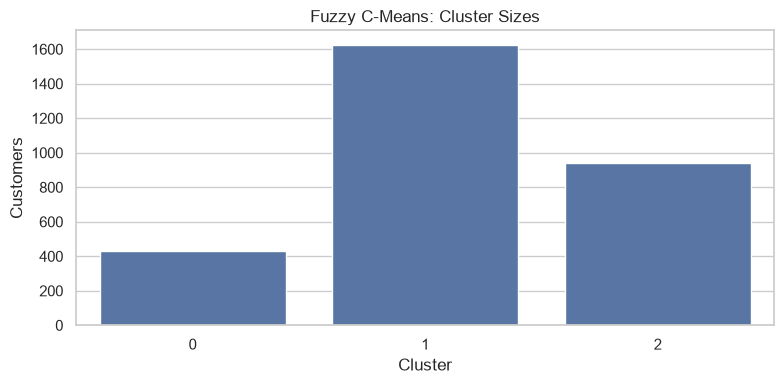

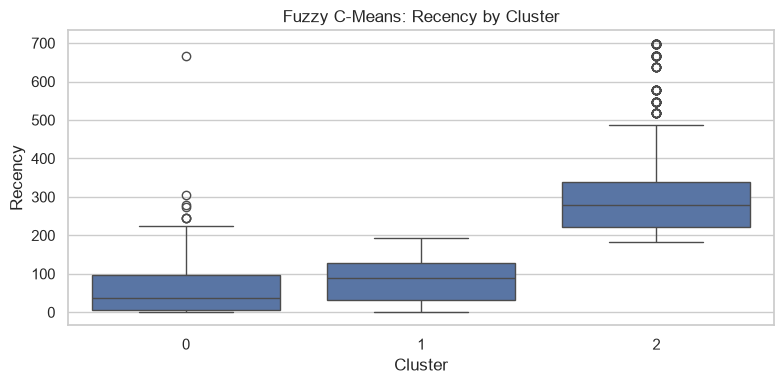

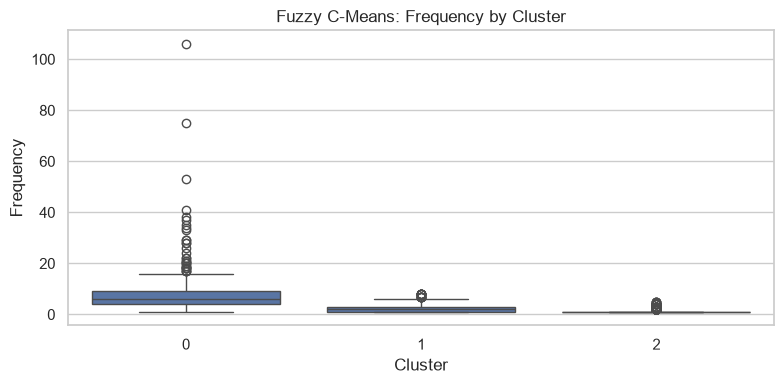

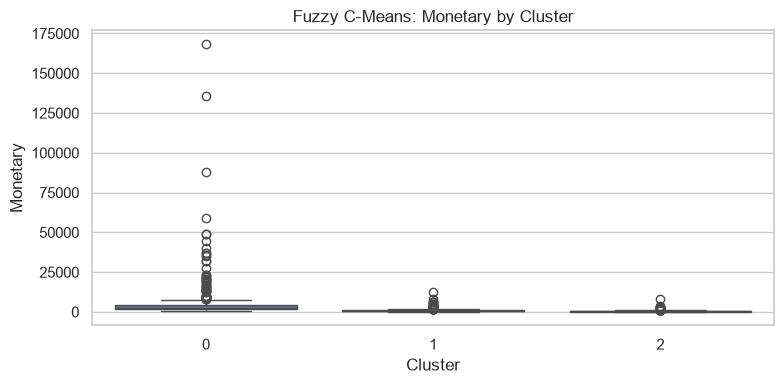

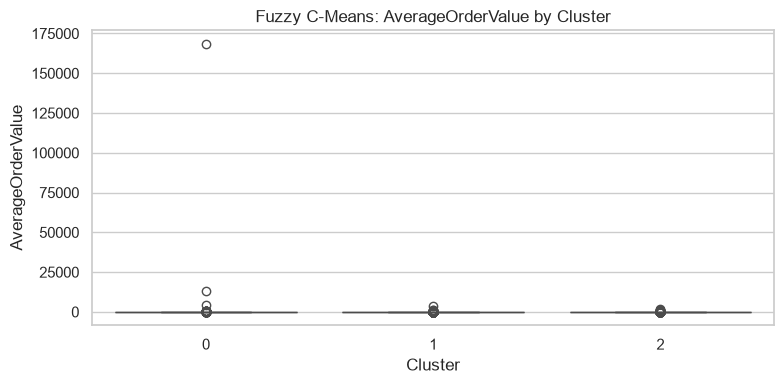

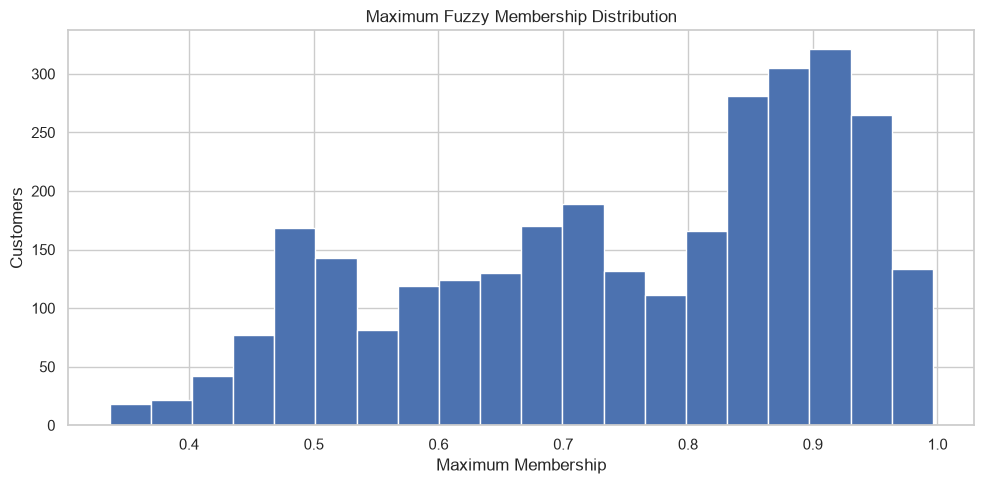

In [19]:
def fuzzy_cmeans(X, c, m=2.0, max_iter=150, tol=1e-5, random_state=42):
    rng = np.random.default_rng(random_state)
    n = X.shape[0]
    U = rng.random((n, c))
    U = U / U.sum(axis=1, keepdims=True)
    for _ in range(max_iter):
        U_old = U.copy()
        Um = U ** m
        centers = (Um.T @ X) / Um.sum(axis=0)[:, None]
        dist = np.maximum(np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2), 1e-8)
        power = 2.0 / (m - 1.0)
        ratios = (dist[:, :, None] / dist[:, None, :]) ** power
        U = 1.0 / ratios.sum(axis=2)
        if np.linalg.norm(U - U_old) < tol:
            break
    labels = U.argmax(axis=1)
    objective = float(np.sum((U ** m) * (dist ** 2)))
    return centers, U, labels, objective

fcm_rows = []
fcm_models = {}
for c in range(2, 8):
    centers, U, labels, objective = fuzzy_cmeans(X_scaled, c, random_state=RANDOM_STATE)
    fcm_rows.append({"C": c, "Objective": objective, "Partition Coefficient": float(np.mean(U ** 2)), **evaluate_labels(X_scaled, labels)})
    fcm_models[c] = (centers, U, labels, objective)
fcm_results = pd.DataFrame(fcm_rows)
display(fcm_results)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(fcm_results["C"], fcm_results["Objective"], marker="o")
axes[0].set_title("Fuzzy C-Means Objective")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Objective")
axes[1].plot(fcm_results["C"], fcm_results["Partition Coefficient"], marker="o")
axes[1].set_title("Fuzzy C-Means Partition Coefficient")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Partition Coefficient")
plt.tight_layout()
plt.show()
best_fcm_c = int(fcm_results.loc[fcm_results["Silhouette"].idxmax(), "C"])
fcm_centers, fcm_membership, fcm_labels, fcm_objective = fcm_models[best_fcm_c]
print("Selected clusters:", best_fcm_c)
display(pd.DataFrame([evaluate_labels(X_scaled, fcm_labels)]))
plot_clusters(fcm_labels, "Fuzzy C-Means Clusters in PCA Space")
fcm_profile = show_profile(fcm_labels, "Fuzzy C-Means")
plt.figure(figsize=(10, 5))
plt.hist(fcm_membership.max(axis=1), bins=20)
plt.title("Maximum Fuzzy Membership Distribution")
plt.xlabel("Maximum Membership")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()


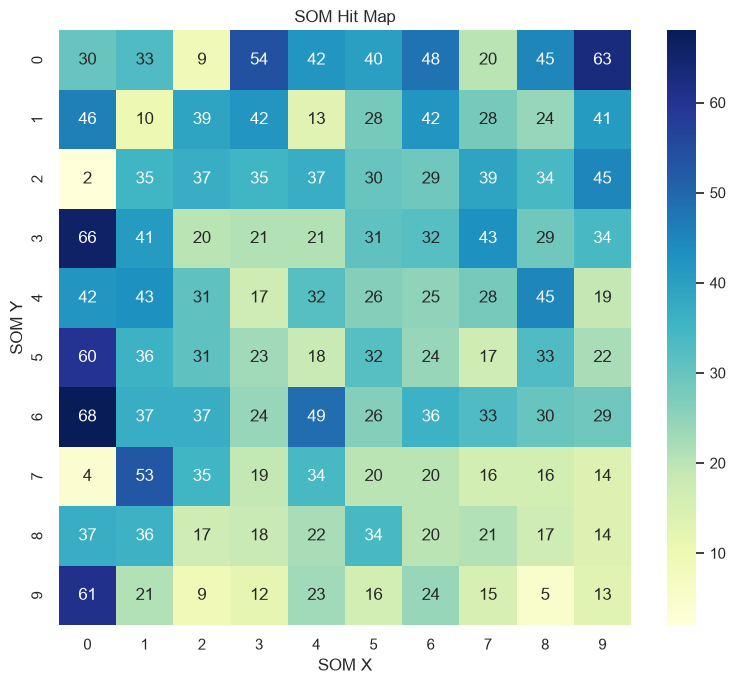

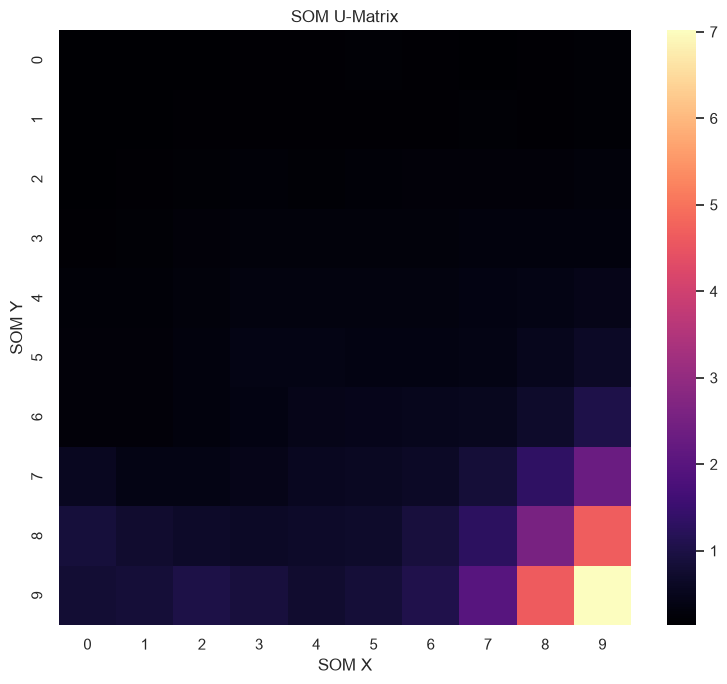

,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,0,0.873352,1013.263205,0.952925


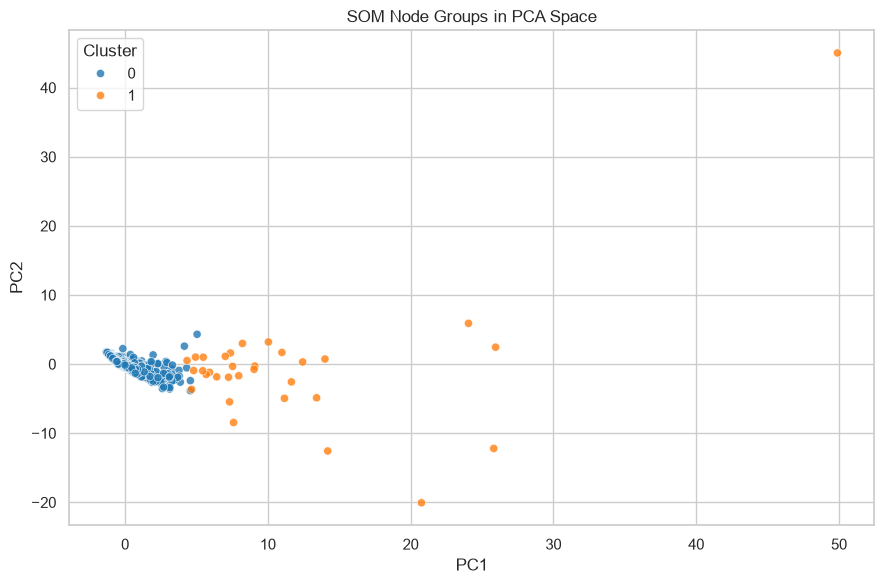

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
0,126.0,2.0,458.43,261.0,26.0,17.97
1,31.0,20.0,21796.57,15261.5,117.5,117.33


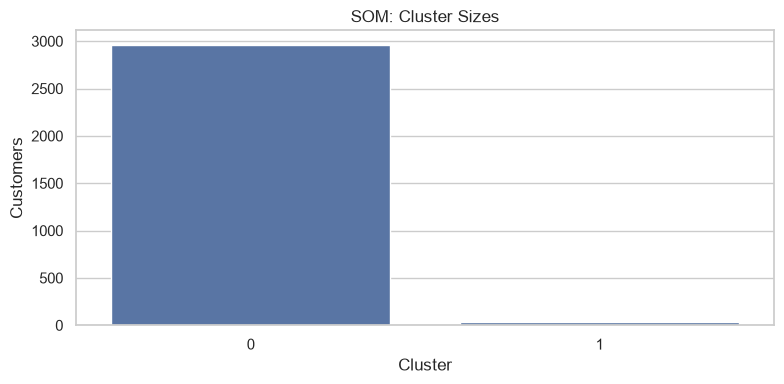

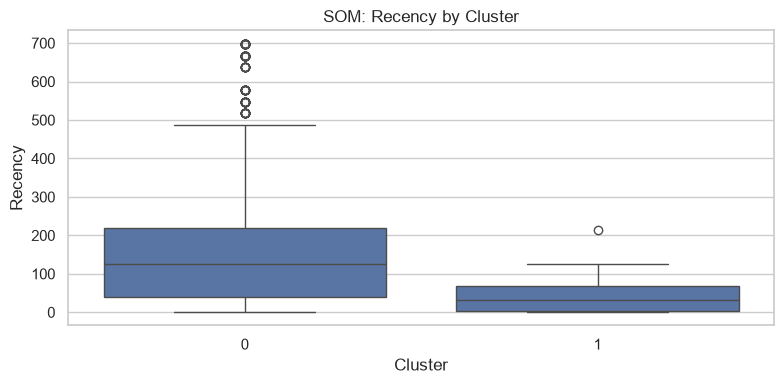

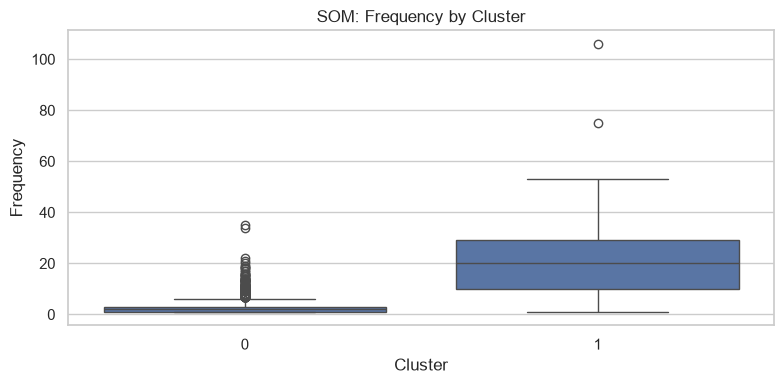

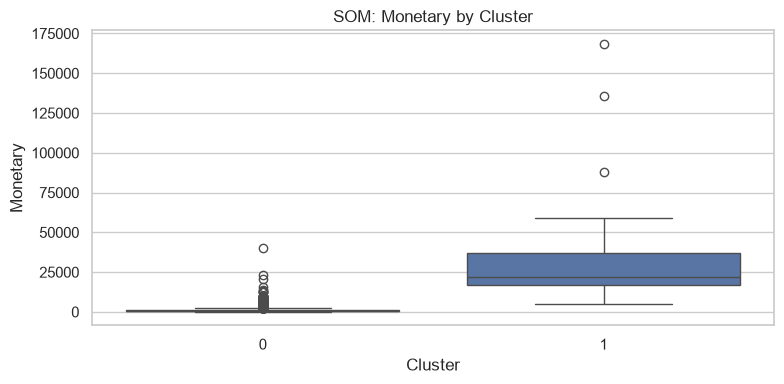

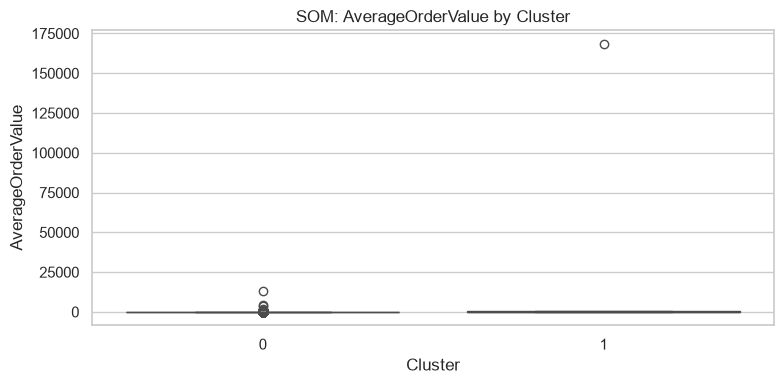

In [20]:
def train_som(X, grid_x=8, grid_y=8, epochs=20, learning_rate=0.4, sigma=None, random_state=42):
    rng = np.random.default_rng(random_state)
    n, d = X.shape
    weights = rng.normal(0, 1, size=(grid_x, grid_y, d))
    sigma = sigma or max(grid_x, grid_y) / 2
    locations = np.array([(i, j) for i in range(grid_x) for j in range(grid_y)])
    total_steps = max(1, epochs * n)
    step = 0
    for epoch in range(epochs):
        for idx in rng.permutation(n):
            sample = X[idx]
            flat_weights = weights.reshape(-1, d)
            bmu_flat = np.argmin(np.linalg.norm(flat_weights - sample, axis=1))
            bx, by = divmod(bmu_flat, grid_y)
            progress = step / total_steps
            lr = learning_rate * (1 - progress)
            current_sigma = max(0.5, sigma * (1 - progress))
            for i in range(grid_x):
                for j in range(grid_y):
                    dist_sq = (i - bx) ** 2 + (j - by) ** 2
                    influence = np.exp(-dist_sq / (2 * current_sigma ** 2))
                    weights[i, j] += lr * influence * (sample - weights[i, j])
            step += 1
    return weights

som_grid = min(10, max(4, int(np.sqrt(len(X_scaled) / 5))))
som_weights = train_som(X_scaled, grid_x=som_grid, grid_y=som_grid, epochs=12, random_state=RANDOM_STATE)
flat_som = som_weights.reshape(-1, X_scaled.shape[1])
som_bmu = np.argmin(np.linalg.norm(X_scaled[:, None, :] - flat_som[None, :, :], axis=2), axis=1)
som_counts = np.bincount(som_bmu, minlength=som_grid * som_grid).reshape(som_grid, som_grid)
plt.figure(figsize=(8, 7))
sns.heatmap(som_counts, annot=True, fmt="d", cmap="YlGnBu")
plt.title("SOM Hit Map")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")
plt.tight_layout()
plt.show()
som_u_matrix = np.zeros((som_grid, som_grid))
for i in range(som_grid):
    for j in range(som_grid):
        neighbors = []
        for di, dj in [(1,0),(-1,0),(0,1),(0,-1)]:
            ni, nj = i + di, j + dj
            if 0 <= ni < som_grid and 0 <= nj < som_grid:
                neighbors.append(np.linalg.norm(som_weights[i, j] - som_weights[ni, nj]))
        som_u_matrix[i, j] = np.mean(neighbors) if neighbors else 0
plt.figure(figsize=(8, 7))
sns.heatmap(som_u_matrix, cmap="magma")
plt.title("SOM U-Matrix")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")
plt.tight_layout()
plt.show()
som_node_labels = KMeans(n_clusters=best_kmeans_k, random_state=RANDOM_STATE, n_init=10).fit_predict(flat_som)
som_labels = som_node_labels[som_bmu]
display(pd.DataFrame([evaluate_labels(X_scaled, som_labels)]))
plot_clusters(som_labels, "SOM Node Groups in PCA Space")
som_profile = show_profile(som_labels, "SOM")


,eps,min_samples,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,0.4,5,4,244,0.411772,565.252990,0.512917
2,0.4,15,4,364,0.346203,590.277484,0.504275
1,0.4,10,4,303,0.285333,559.731981,0.575247
3,0.6,5,3,143,0.240173,13.198574,0.701151
4,0.6,10,1,173,NaN,NaN,NaN
5,0.6,15,1,195,NaN,NaN,NaN
6,0.8,5,1,84,NaN,NaN,NaN
7,0.8,10,1,104,NaN,NaN,NaN
8,0.8,15,1,117,NaN,NaN,NaN
9,1.0,5,1,62,NaN,NaN,NaN


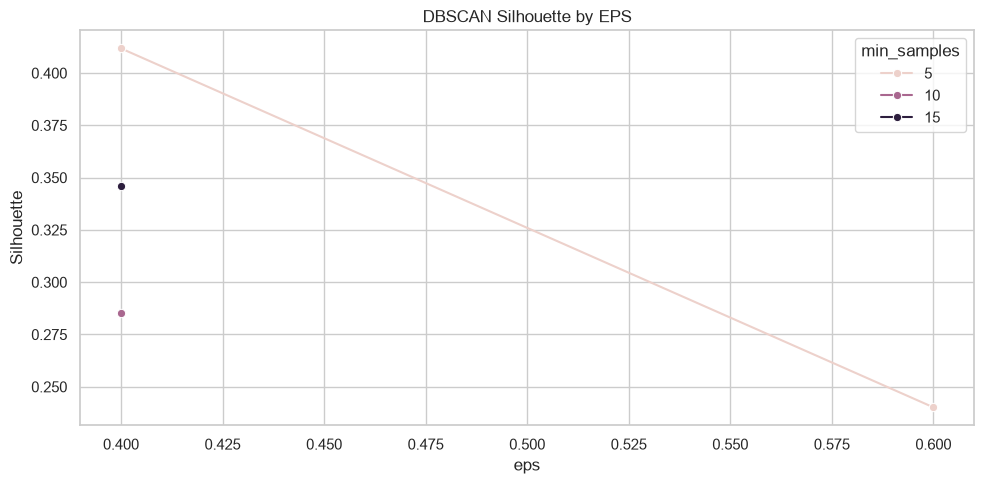

,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,4,244,0.411772,565.25299,0.512917


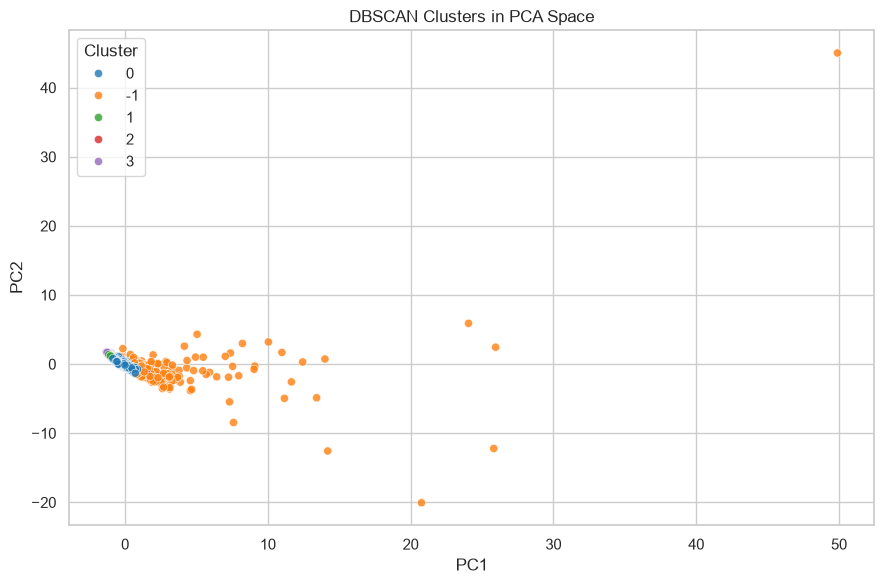

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
-1,37.0,7.0,3754.41,2372.0,127.5,25.26
0,126.0,1.0,438.07,250.0,25.0,17.87
1,486.0,1.0,256.32,110.0,15.0,17.16
2,36.0,10.0,3366.75,1971.0,133.5,20.41
3,667.0,1.0,207.50,102.0,11.0,18.06


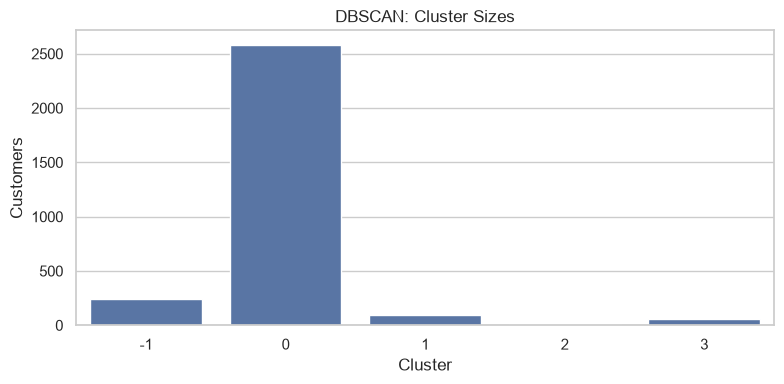

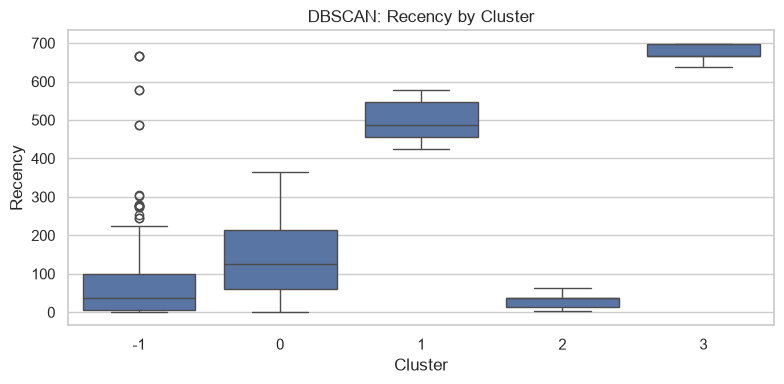

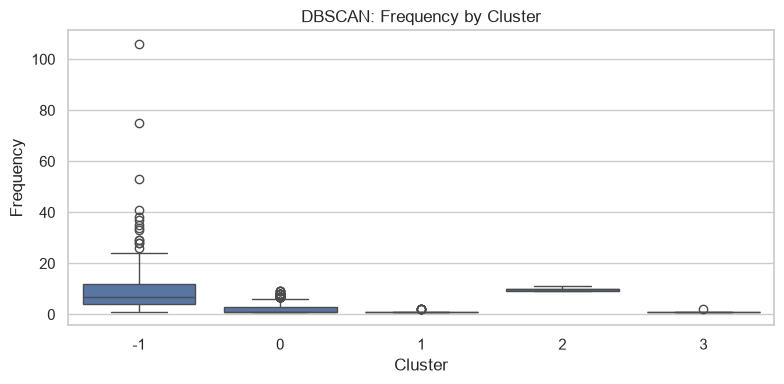

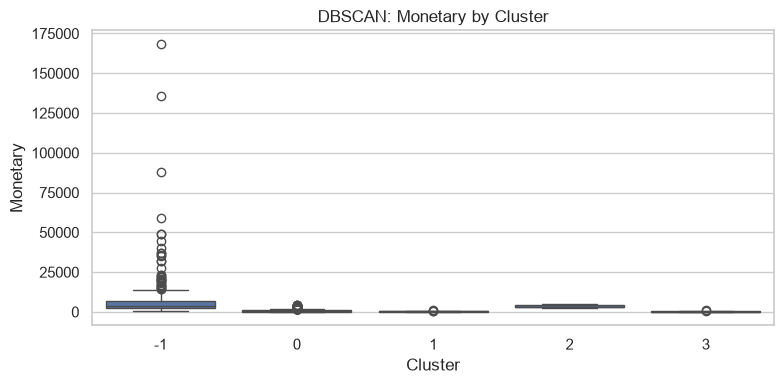

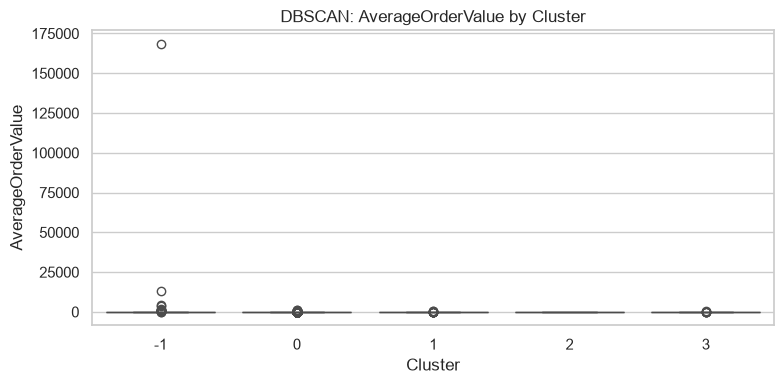

In [21]:
dbscan_rows = []
dbscan_models = {}
for eps in [0.4, 0.6, 0.8, 1.0, 1.2, 1.5, 2.0]:
    for min_samples in [5, 10, 15]:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)
        dbscan_rows.append({"eps": eps, "min_samples": min_samples, **evaluate_labels(X_scaled, labels)})
        dbscan_models[(eps, min_samples)] = (model, labels)
dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.sort_values("Silhouette", ascending=False).head(15))
plt.figure(figsize=(10, 5))
sns.lineplot(data=dbscan_results, x="eps", y="Silhouette", hue="min_samples", marker="o")
plt.title("DBSCAN Silhouette by EPS")
plt.tight_layout()
plt.show()
valid_db = dbscan_results.dropna(subset=["Silhouette"])
if len(valid_db):
    best_db = valid_db.loc[valid_db["Silhouette"].idxmax()]
    dbscan_model, dbscan_labels = dbscan_models[(float(best_db["eps"]), int(best_db["min_samples"]))]
else:
    dbscan_model = DBSCAN(eps=1.0, min_samples=10)
    dbscan_labels = dbscan_model.fit_predict(X_scaled)
display(pd.DataFrame([evaluate_labels(X_scaled, dbscan_labels)]))
plot_clusters(dbscan_labels, "DBSCAN Clusters in PCA Space")
dbscan_profile = show_profile(dbscan_labels, "DBSCAN")


,K,BIC,AIC,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,2,-12074.327915,-12404.623104,2,0,0.522536,357.624114,1.721451
1,3,-13901.031676,-14399.477142,3,0,0.451179,873.474579,1.146822
2,4,-21873.506262,-22540.102007,4,0,0.166500,577.729386,1.770831
3,5,-22774.381926,-23609.127949,5,0,0.153930,838.618147,1.993964
4,6,-31898.216227,-32901.112528,6,0,0.000492,669.287531,2.062029
5,7,-31177.716457,-32348.763035,7,0,0.005113,815.401988,1.558132
6,8,-32937.056170,-34276.253026,8,0,0.069942,896.087515,1.685895


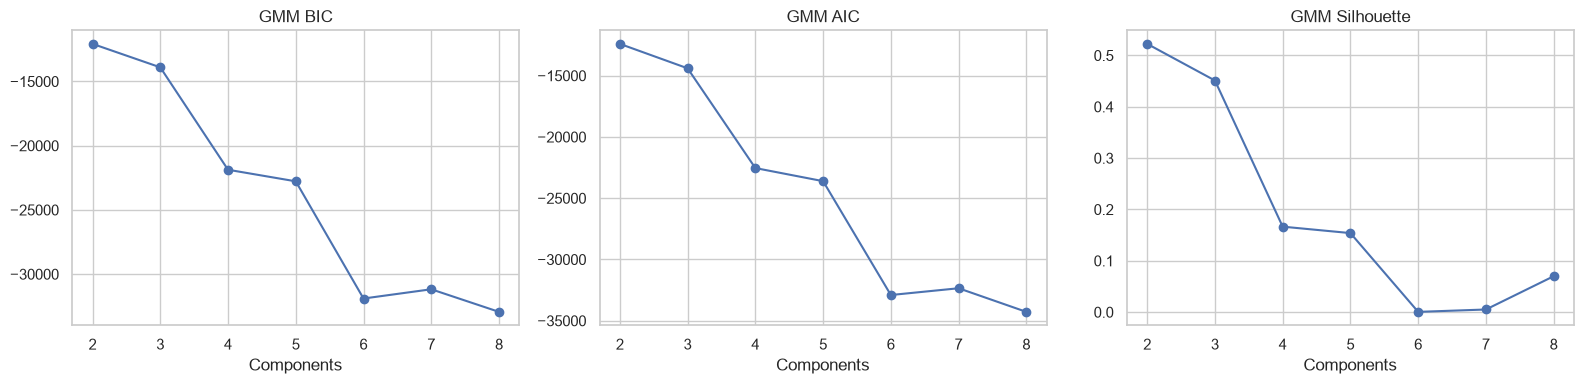

Selected components by BIC: 8


,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,8,0,0.069942,896.087515,1.685895


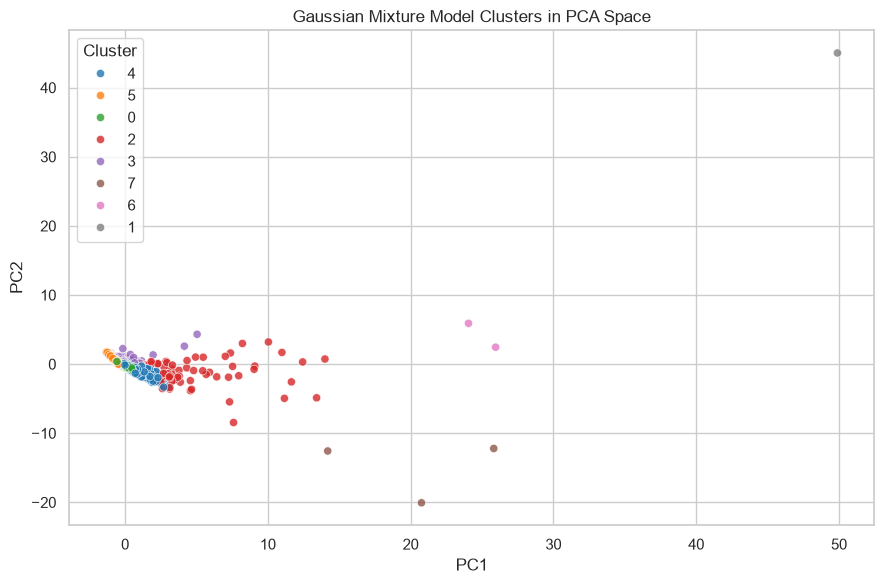

,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AverageOrderValue
Cluster,,,,,,
0,101.0,2.0,643.84,355.0,33.0,18.56
1,90.0,1.0,168469.60,80995.0,1.0,168469.60
2,32.0,11.0,7928.51,4283.0,68.0,68.65
3,152.0,1.0,734.40,504.0,3.0,179.00
4,62.0,5.0,1745.52,1090.0,95.0,16.52
5,187.0,1.0,244.50,127.0,16.0,16.95
6,46.5,28.5,111785.22,50270.0,252.5,355.59
7,1.0,75.0,17142.19,11450.0,1117.0,6.68


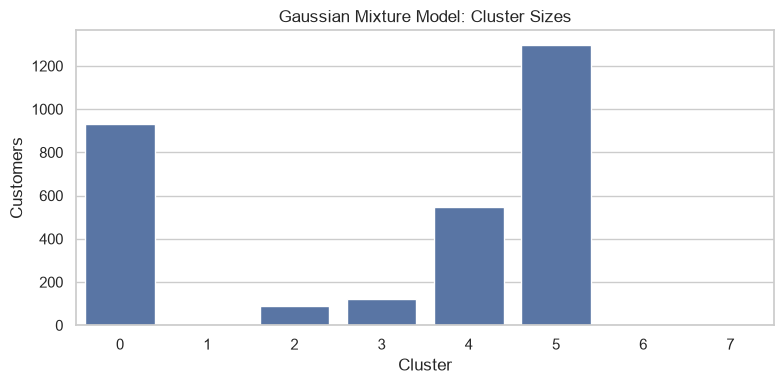

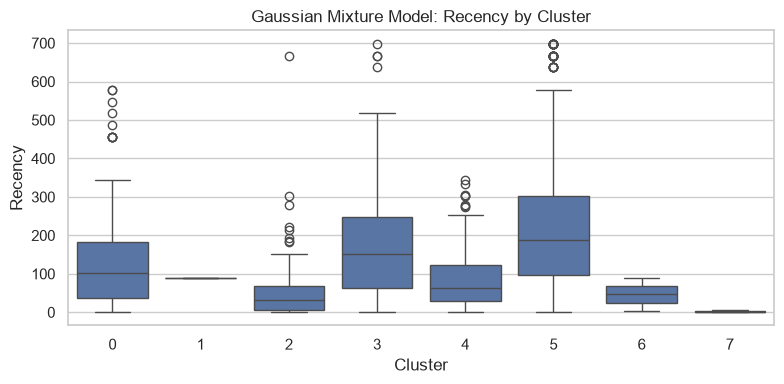

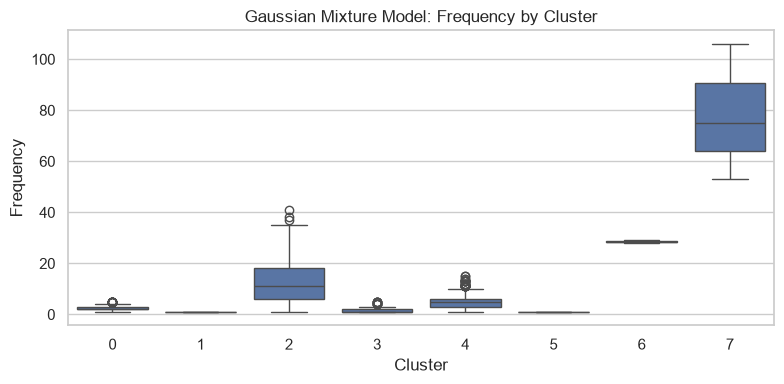

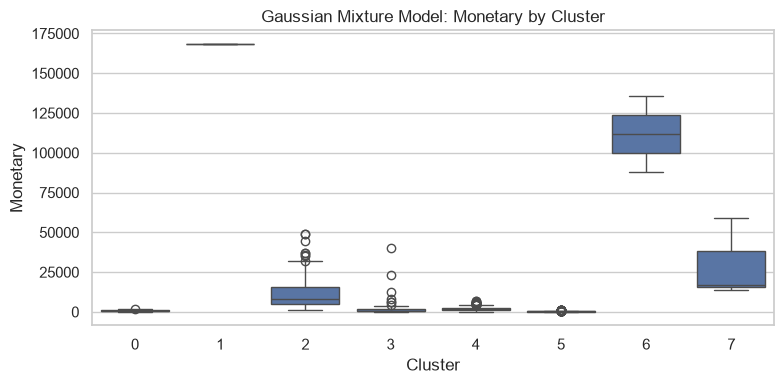

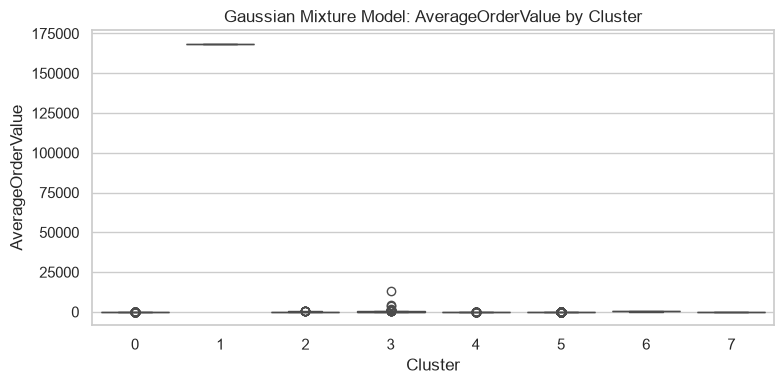

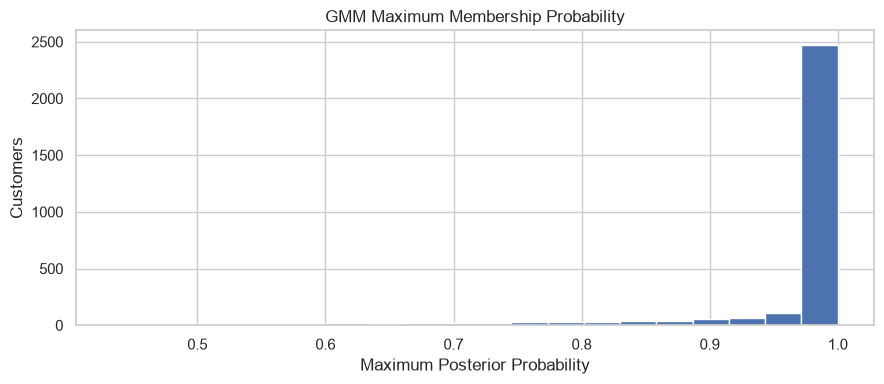

In [22]:
gmm_rows = []
gmm_models = {}
for k in range(2, 9):
    model = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE, n_init=2, reg_covar=1e-5)
    labels = model.fit_predict(X_scaled)
    gmm_rows.append({"K": k, "BIC": model.bic(X_scaled), "AIC": model.aic(X_scaled), **evaluate_labels(X_scaled, labels)})
    gmm_models[k] = (model, labels)
gmm_results = pd.DataFrame(gmm_rows)
display(gmm_results)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(gmm_results["K"], gmm_results["BIC"], marker="o")
axes[0].set_title("GMM BIC")
axes[0].set_xlabel("Components")
axes[1].plot(gmm_results["K"], gmm_results["AIC"], marker="o")
axes[1].set_title("GMM AIC")
axes[1].set_xlabel("Components")
axes[2].plot(gmm_results["K"], gmm_results["Silhouette"], marker="o")
axes[2].set_title("GMM Silhouette")
axes[2].set_xlabel("Components")
plt.tight_layout()
plt.show()
best_gmm_k = int(gmm_results.loc[gmm_results["BIC"].idxmin(), "K"])
gmm_model, gmm_labels = gmm_models[best_gmm_k]
gmm_probabilities = gmm_model.predict_proba(X_scaled)
print("Selected components by BIC:", best_gmm_k)
display(pd.DataFrame([evaluate_labels(X_scaled, gmm_labels)]))
plot_clusters(gmm_labels, "Gaussian Mixture Model Clusters in PCA Space")
gmm_profile = show_profile(gmm_labels, "Gaussian Mixture Model")
plt.figure(figsize=(9, 4))
plt.hist(gmm_probabilities.max(axis=1), bins=20)
plt.title("GMM Maximum Membership Probability")
plt.xlabel("Maximum Posterior Probability")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()


,Model,Clusters,Noise Points,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,K-Means,2,0,0.971924,1106.896700,0.019020
1,Agglomerative,2,0,0.971924,1106.896700,0.019020
2,K-Medoids,3,0,0.330065,377.823049,1.101776
3,Fuzzy C-Means,3,0,0.353686,512.064587,1.140558
4,Gaussian Mixture,8,0,0.069942,896.087515,1.685895
5,SOM,2,0,0.873352,1013.263205,0.952925
6,DBSCAN,4,244,0.411772,565.252990,0.512917


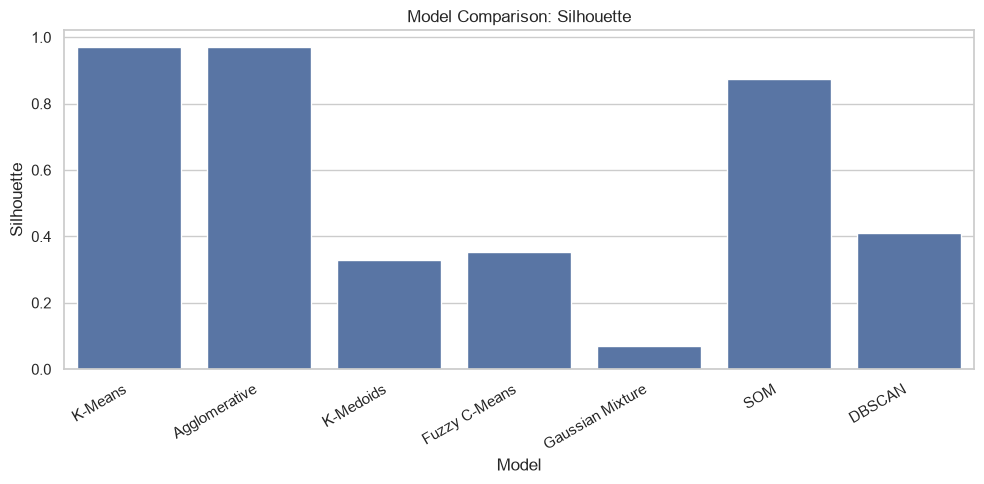

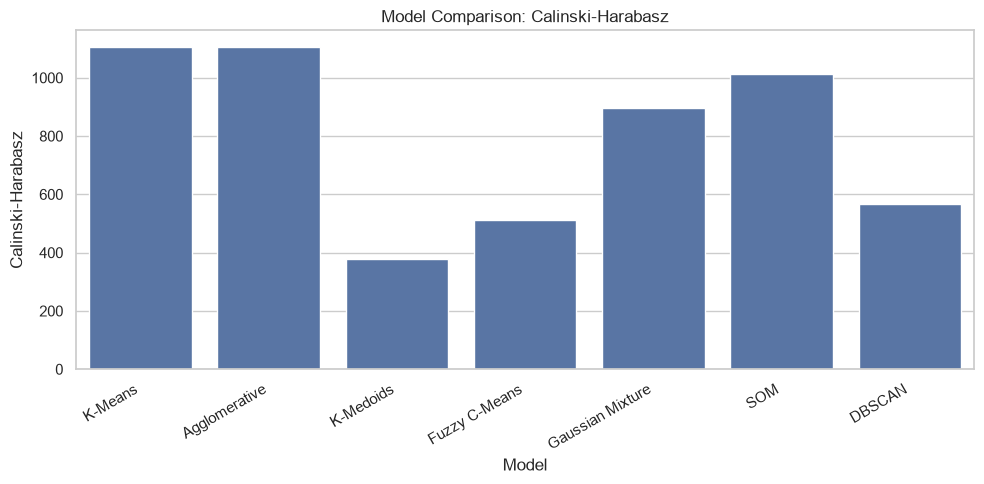

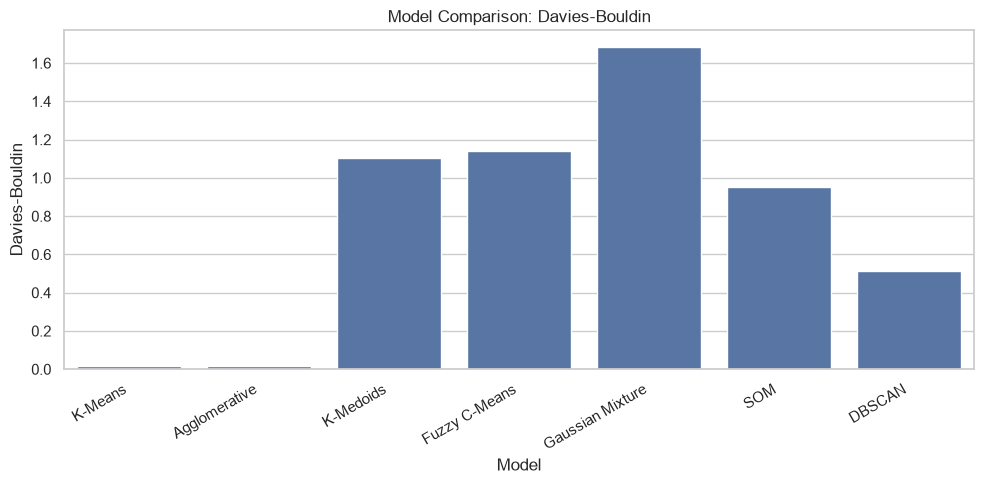

In [23]:
model_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative": agg_labels,
    "K-Medoids": kmedoid_labels,
    "Fuzzy C-Means": fcm_labels,
    "Gaussian Mixture": gmm_labels,
    "SOM": som_labels,
    "DBSCAN": dbscan_labels
}
comparison_rows = []
for name, labels in model_labels.items():
    comparison_rows.append({"Model": name, **evaluate_labels(X_scaled, labels)})
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
for metric in ["Silhouette", "Calinski-Harabasz", "Davies-Bouldin"]:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=comparison_df, x="Model", y=metric)
    plt.title(f"Model Comparison: {metric}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
